# ConvNeXt-Tiny: Document Image Classification

**Tujuan.** Melatih dan mengevaluasi ConvNeXt-Tiny untuk memprediksi 16 kategori dokumen hasil scan. Notebook memakai split stratified 75/25 agar tiap kelas terwakili di train dan validation.



## 1. Konfigurasi dan perangkat

Tuning dimulai dari checkpoint ConvNeXt baseline. Backbone memakai learning rate lebih kecil daripada classifier. Weight decay, label smoothing, augmentasi ringan, scheduler, dan early stopping membantu mengendalikan generalisasi. Jika checkpoint tuning sudah tersedia, notebook melanjutkan dari checkpoint itu.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
import torch
from IPython.display import Image as NotebookImage, display
from scripts import config
from scripts.train import train_model
from scripts.predict import predict_test

print('Device:', config.DEVICE if torch.cuda.is_available() else 'cpu')
if torch.cuda.is_available(): print('GPU:', torch.cuda.get_device_name(0))
print(f"Split validation: {config.VALIDATION_SIZE:.0%} | max epochs: {config.EPOCHS}")
print(f"Batch size: {config.BATCH_SIZE} | image size: {config.IMAGE_SIZE}")
print(f"Backbone LR: {config.BACKBONE_LEARNING_RATE:g} | classifier LR: {config.CLASSIFIER_LEARNING_RATE:g}")

Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
Split validation: 25% | max epochs: 4
Batch size: 16 | image size: 224
Backbone LR: 3e-05 | classifier LR: 0.0003


## 2. Contoh gambar per kelas

Pipeline menyimpan satu contoh gambar untuk setiap label pada panel 4?4. Panel ini membantu memeriksa variasi tata letak dokumen sebelum menilai kesalahan model.

## 3. Fine-tuning dan pemantauan generalisasi

Checkpoint dipilih berdasarkan validation loss terendah. Training berhenti lebih awal jika validation loss tidak membaik. Generalization gap di tabel adalah selisih akurasi train dan validation. Gap yang besar, atau validation loss yang naik saat train loss turun, dapat menunjukkan overfitting. Jika kedua loss masih tinggi, model mungkin belum cukup fit.

Validation:   0%|          | 0/501 [00:07<?, ?it/s]

Train:   0%|          | 0/1501 [00:07<?, ?it/s]

Validation:   0%|          | 0/501 [00:07<?, ?it/s]

{"epoch": 1, "train_loss": 0.6158179554002761, "train_accuracy": 0.9065494542121489, "validation_loss": 0.76260172412658, "validation_accuracy": 0.8518935133108362, "generalization_gap": 0.05465594090131276, "backbone_learning_rate": 3e-05, "classifier_learning_rate": 0.0003}


Train:   0%|          | 0/1501 [00:06<?, ?it/s]

...

Validation:   0%|          | 0/501 [00:07<?, ?it/s]

{"epoch": 3, "train_loss": 0.47127031208415715, "train_accuracy": 0.95537871844013, "validation_loss": 0.7709143789071409, "validation_accuracy": 0.8577677790276216, "generalization_gap": 0.09761093941250842, "backbone_learning_rate": 1.5e-05, "classifier_learning_rate": 0.00015}
Early stopping at epoch 3; validation loss stopped improving.


Validation:   0%|          | 0/501 [00:09<?, ?it/s]

Train rows: 24002 | validation rows: 8001
Device: cuda | best epoch: 1
Best validation accuracy: 0.8519
Best validation loss: 0.7626
Confusion matrix shape: (16, 16)
                        precision    recall  f1-score   support

         advertisement       0.88      0.89      0.88       503
                budget       0.77      0.83      0.80       501
                 email       0.97      0.98      0.98       503
           file_folder       0.89      0.97      0.93       506
                  form       0.71      0.66      0.68       501
           handwritten       0.91      0.96      0.93       507
               invoice       0.86      0.84      0.85       495
                letter       0.85      0.86      0.86       493
                  memo       0.92      0.88      0.90       499
          news_article       0.84      0.86      0.85       493
          presentation       0.75      0.77      0.76       498
         questionnaire       0.75      0.81      0.78       487
 

,epoch,train_loss,train_accuracy,validation_loss,validation_accuracy,generalization_gap,backbone_learning_rate,classifier_learning_rate
0,0,NaN,NaN,0.985588,0.807899,NaN,NaN,NaN
1,1,0.615818,0.906549,0.762602,0.851894,0.054656,0.000030,0.00030
2,2,0.526022,0.934880,0.775427,0.854893,0.079987,0.000030,0.00030
3,3,0.471270,0.955379,0.770914,0.857768,0.097611,0.000015,0.00015


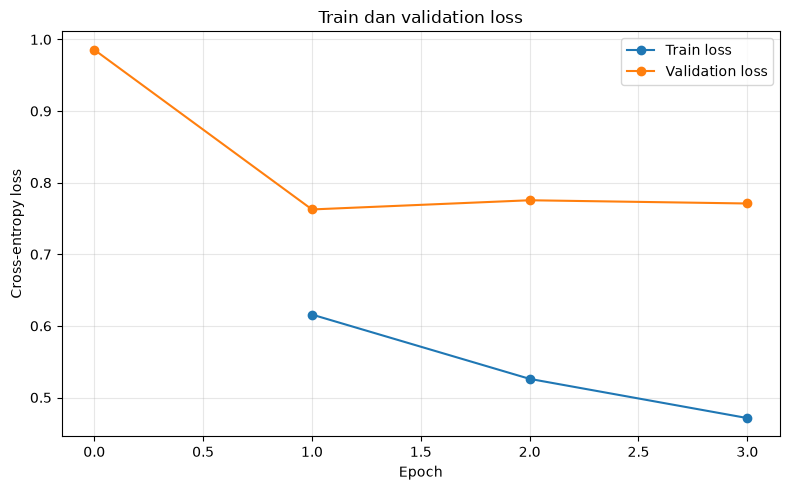

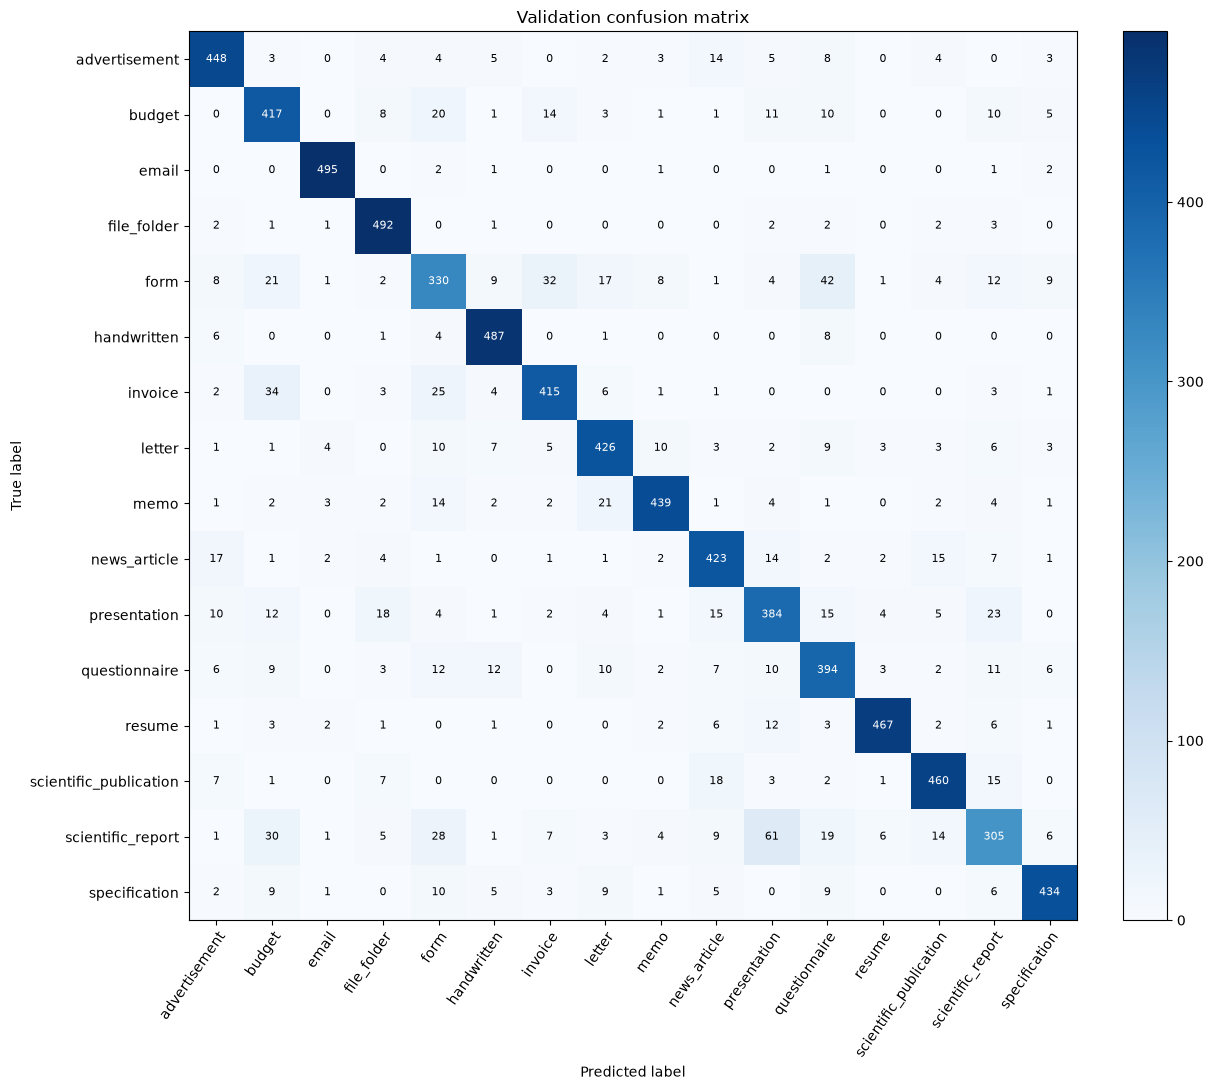

In [2]:
history, y_true, y_pred = train_model(epochs=config.EPOCHS)
history_df = pd.DataFrame(history)
display(history_df)

## 4. Kurva loss dan confusion matrix

Kurva membandingkan train loss dan validation loss per epoch. Confusion matrix berisi hitungan prediksi untuk setiap pasangan label sebenarnya dan label prediksi; nilai diagonal menunjukkan prediksi benar.

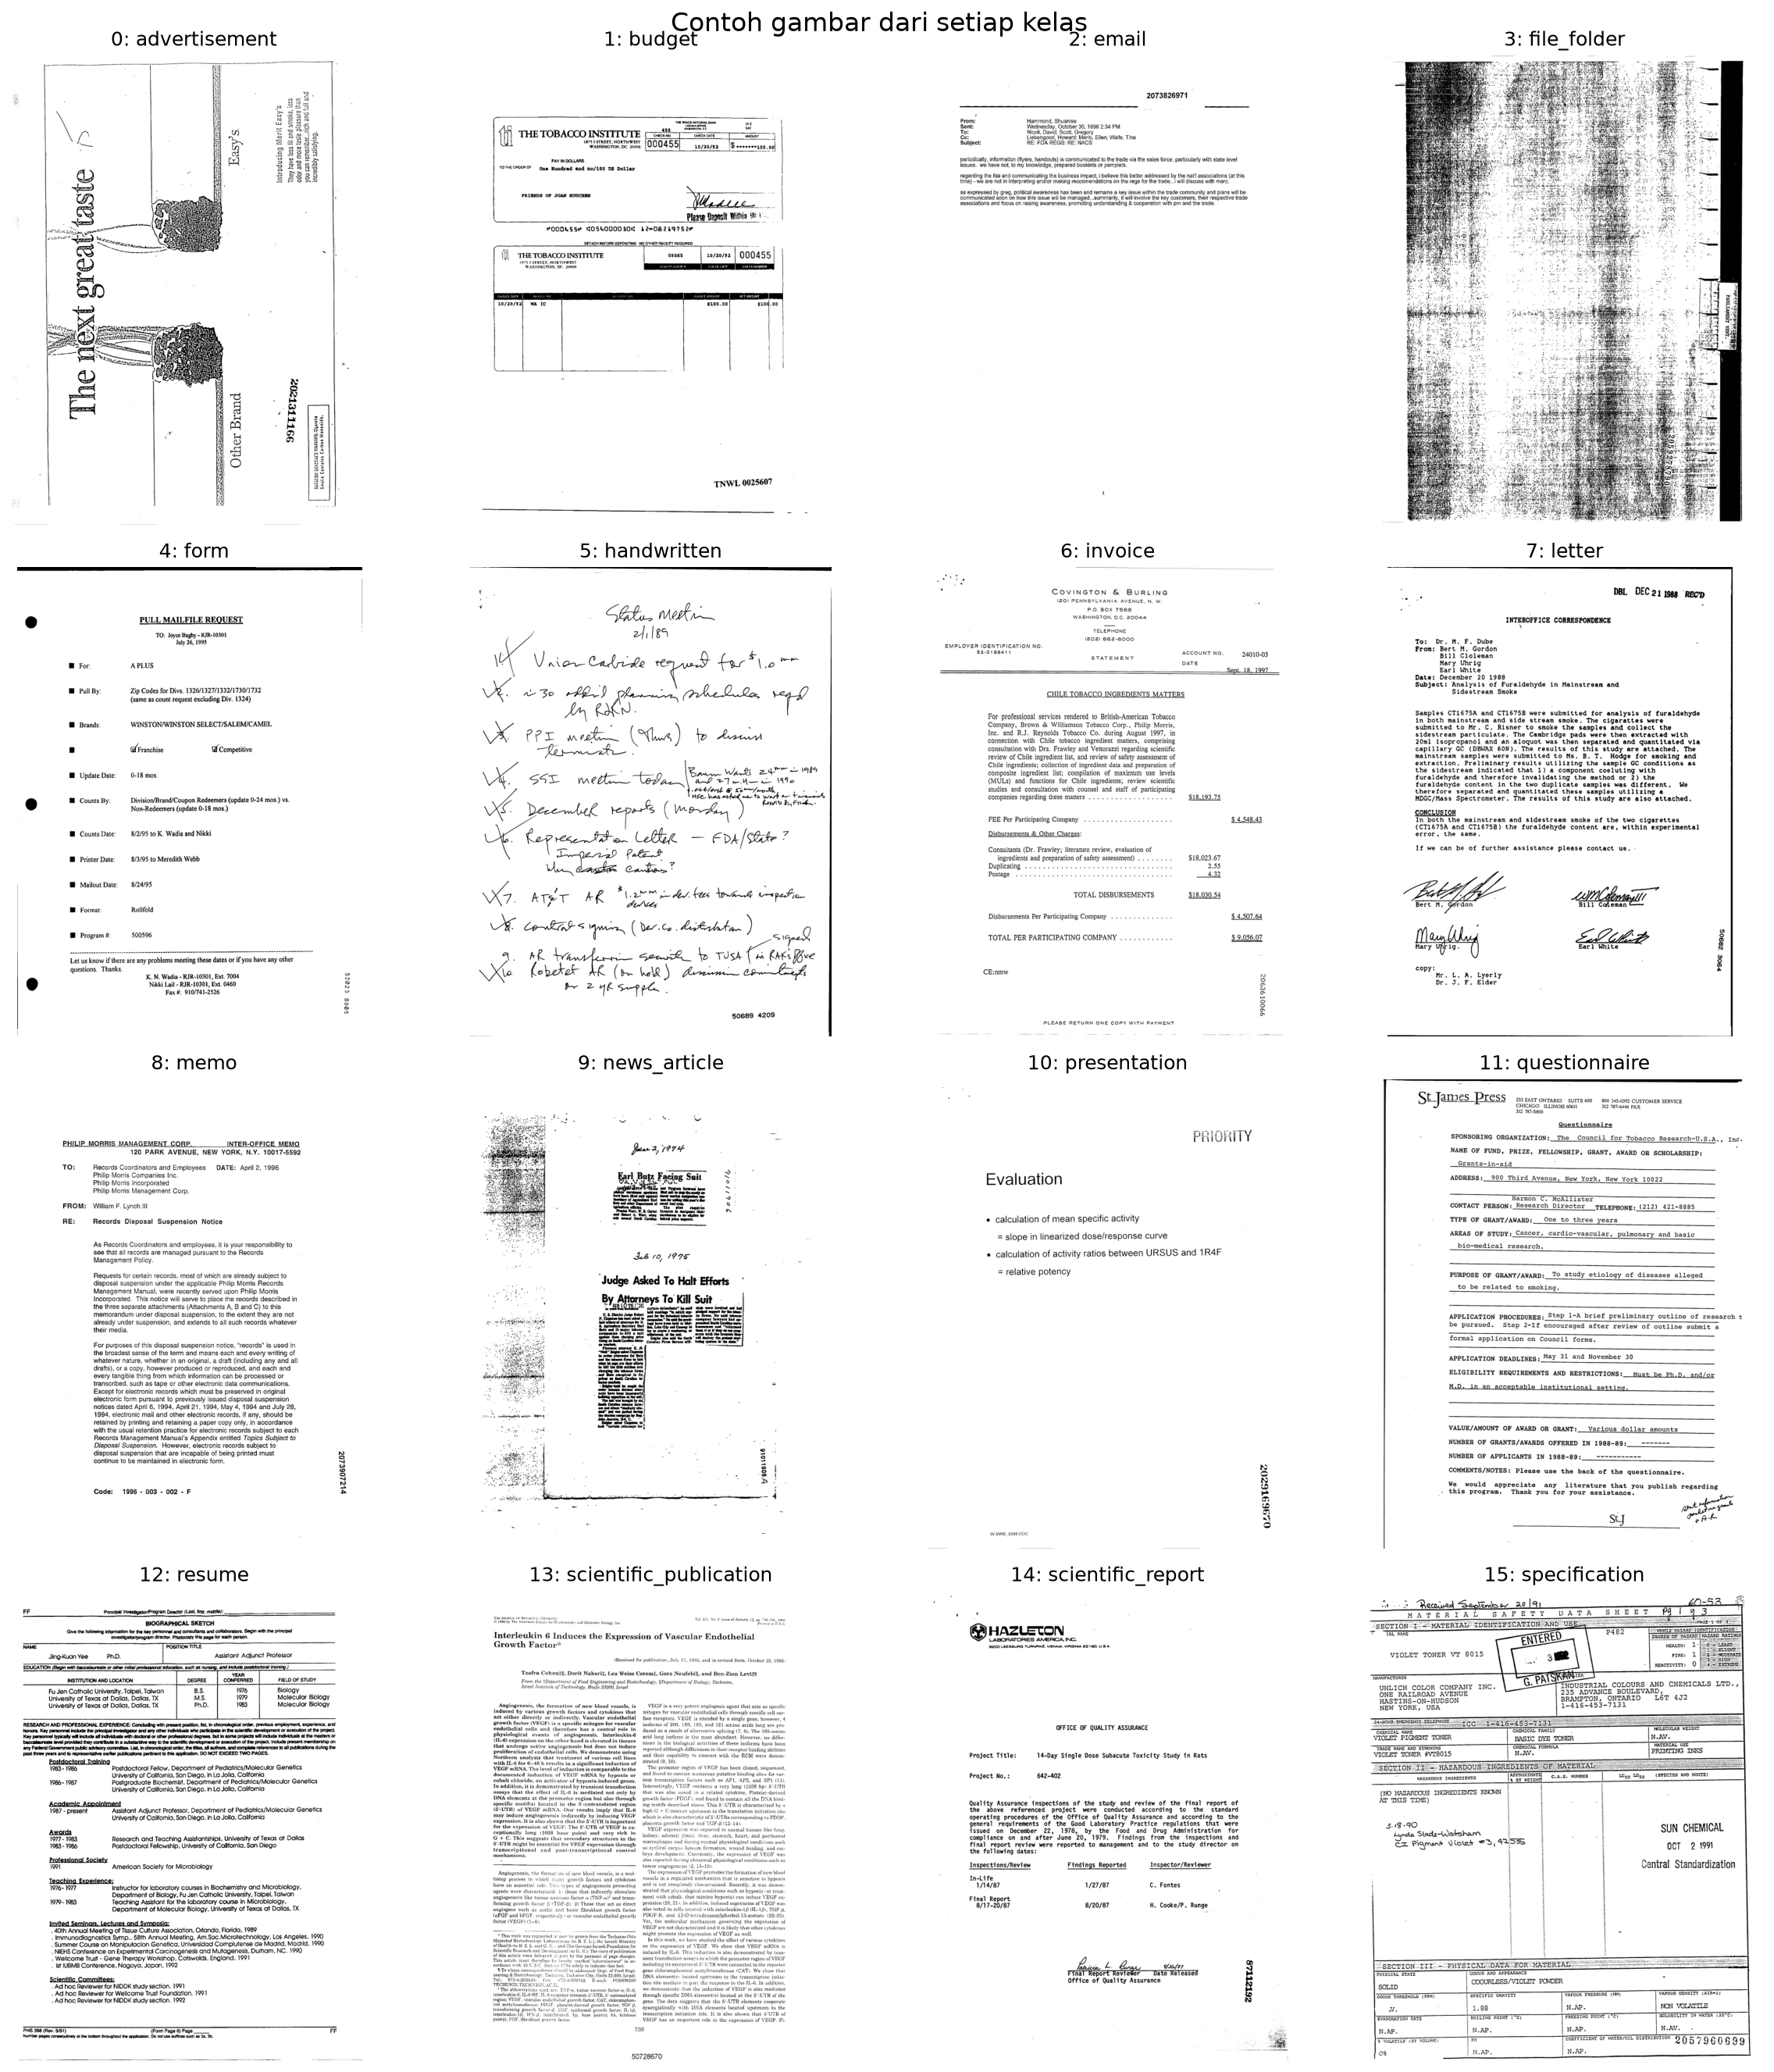

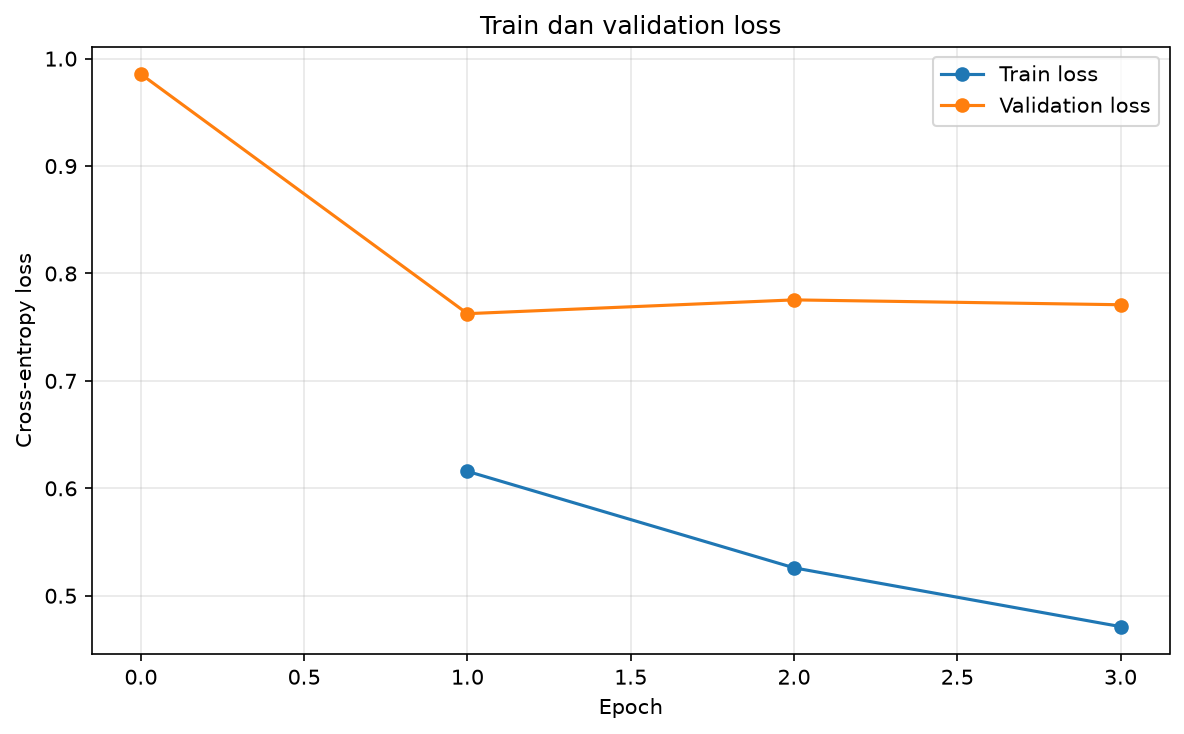

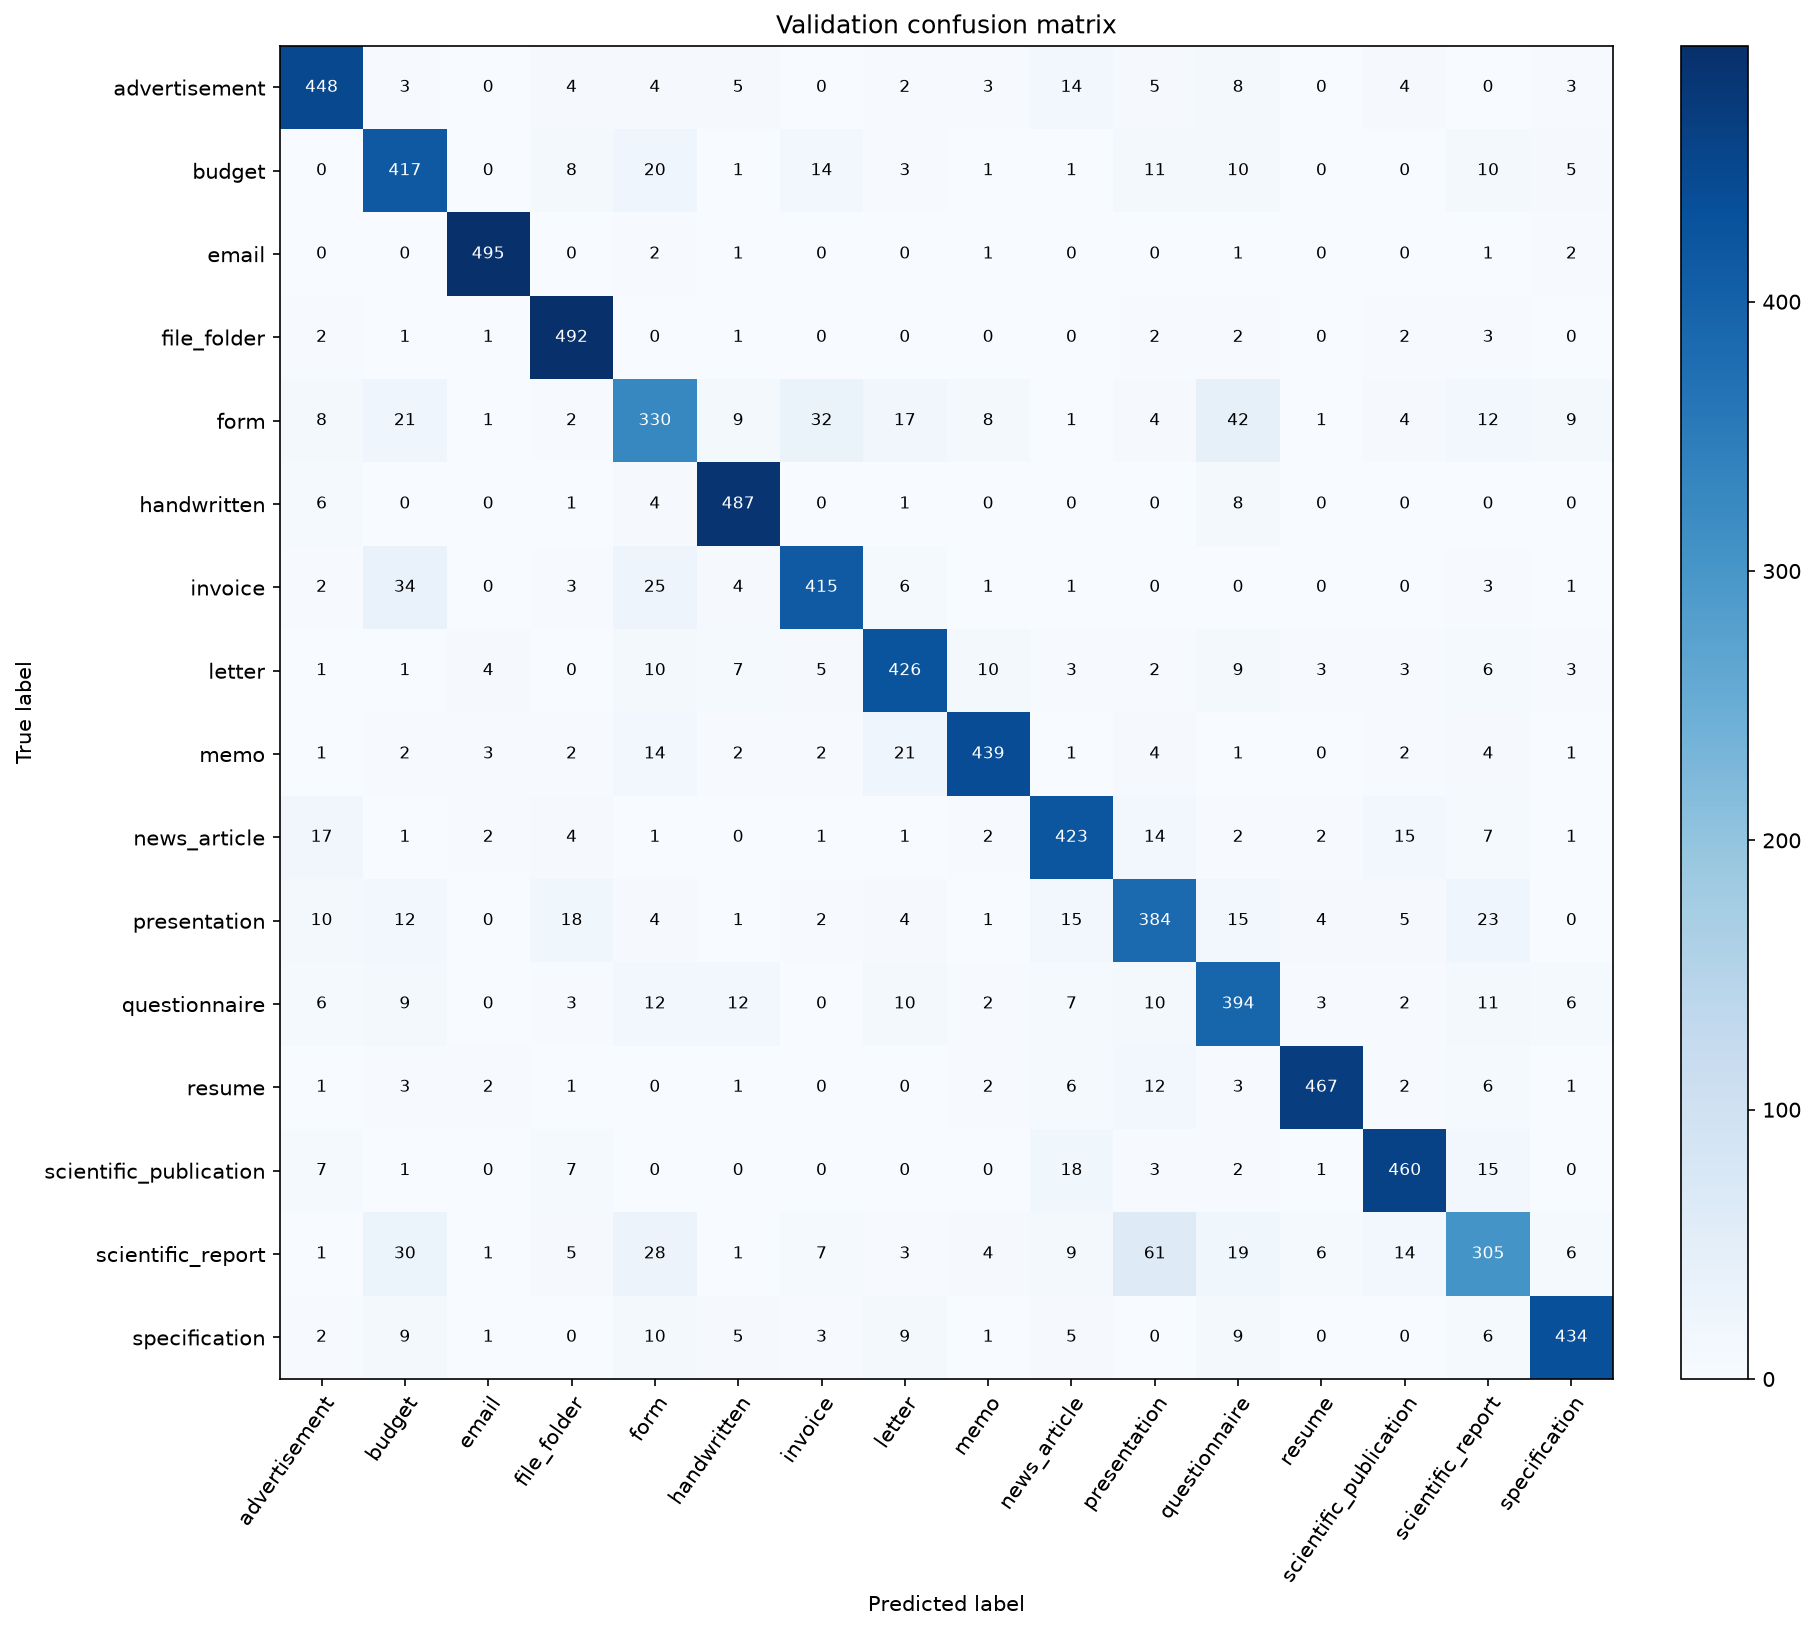

In [3]:
display(NotebookImage(filename=str(config.FIGURE_DIR / 'convnext_tuned_examples_per_class.png')))
display(NotebookImage(filename=str(config.FIGURE_DIR / 'convnext_tuned_validation_loss.png')))
display(NotebookImage(filename=str(config.FIGURE_DIR / 'convnext_tuned_confusion_matrix.png')))

## 5. Submission Kaggle

Prediksi disimpan ke `submissions/submission_convnext_tuned.csv` dengan kolom `id,label` dan urutan yang sama seperti `test.csv`.

In [4]:
submission = predict_test()
display(submission.head())
print(f"Rows: {len(submission)} | predicted classes: {submission['label'].nunique()}")

Predict test:   0%|          | 0/500 [00:04<?, ?it/s]

Saved 7994 rows to C:\Users\Akmal sharif Ramdan\Documents\Tugas2_SML\submissions\submission_convnext_tuned.csv
{0: 512, 1: 523, 2: 510, 3: 532, 4: 496, 5: 519, 6: 483, 7: 507, 8: 460, 9: 500, 10: 529, 11: 487, 12: 493, 13: 515, 14: 450, 15: 478}


,id,label
0,test_00001,0
1,test_00002,0
2,test_00003,6
3,test_00004,4
4,test_00005,13


Rows: 7994 | predicted classes: 16
